## CMPSC 105 Lab 07: Interpreting Hypothesis Tests

Your name(s):Le Minh Hung , Zedan _____________________

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# 1. DATA GENERATION (Run this cell to load your "lab_data")

# Generate doomscolling data
n_users = 1000

user_baselines = np.random.gamma(shape=3.0, scale=40.0, size=n_users)
standard_time = user_baselines + np.random.normal(loc=0, scale=10, size=n_users)
new_time = user_baselines + np.random.normal(loc=1.5, scale=10, size=n_users)
df_doomscrolling = pd.DataFrame({
    'user_id': np.arange(n_users),
    'standard_time': standard_time,
    'new_time': new_time
})
df_doomscrolling['difference'] = df_doomscrolling['new_time'] - df_doomscrolling['standard_time']
df_doomscrolling = df_doomscrolling.sample(frac=1, ignore_index=True)
    

# Generate e-commerce A/B test Data
blue_spending = np.random.normal(loc=42.50, scale=25.0, size=2000)
green_spending = np.random.normal(loc=43.10, scale=25.0, size=2000)
blue_spending = np.clip(blue_spending, a_min=0, a_max=None)
green_spending = np.clip(green_spending, a_min=0, a_max=None)

df_ecommerce = pd.DataFrame({
    'button_color': ['Blue'] * 2000 + ['Green'] * 2000,
    'spending': np.concatenate([blue_spending, green_spending])
})
df_ecommerce = df_ecommerce.sample(frac=1, ignore_index=True)

print("Datasets generated successfully!")


Datasets generated successfully!


### Scenario 1: The E-Commerce A/B Test

An e-commerce company is conducting an **A/B test** to determine the effect of button color on user spending for their shopping app. An A/B test is a controlled experiment where two or more variants of a single variable are compared to determine which performs better. In this case, the variable is the button color, and the outcome is user spending. 

Users are randomly assigned to see either a blue or green button, and their spending is recorded. The goal is to assess whether the button color influences the amount users spend.

In [11]:
print(df_ecommerce.head())
print(df_ecommerce.tail())

  button_color   spending
0         Blue  32.767690
1         Blue   0.000000
2         Blue  19.163350
3         Blue   0.000000
4         Blue  44.084648
     button_color   spending
3995        Green  52.913520
3996        Green  48.564433
3997        Green  42.852749
3998        Green  35.305881
3999         Blue  62.367523


In [4]:
# Calculate the observed difference in means
ecomm_means = df_ecommerce.groupby('button_color')['spending'].mean()
obs_diff_ecomm = ecomm_means['Green'] - ecomm_means['Blue']

print(f"Blue Button Mean: ${ecomm_means['Blue']:.2f}")
print(f"Green Button Mean: ${ecomm_means['Green']:.2f}")
print(f"Observed Difference: ${obs_diff_ecomm:.2f}")


Blue Button Mean: $43.24
Green Button Mean: $43.38
Observed Difference: $0.14


We can test whether the differenece between the green and blue button spending is statistically significant using a permutation test, where we repeatedly shuffle the button color labels and calculate the difference in mean spending between the green and blue buttons. This generates a null distribution of differences, which we can then compare to the observed difference to compute a p-value.

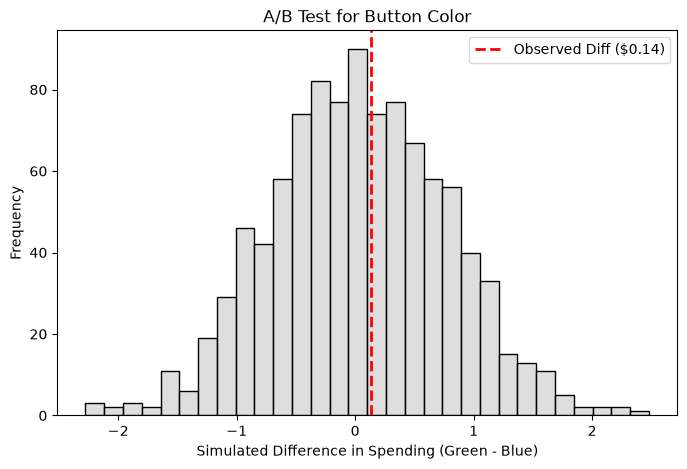

P-value for A/B Test (Button Color): 0.5570


In [5]:
# Permutation test
n_iter = 1000
simulated_diffs_ecomm = np.zeros(n_iter)

spending_vals = df_ecommerce['spending'].values
color_labels = df_ecommerce['button_color'].values

for i in range(n_iter):
    # Shuffle the labels
    shuffled = np.random.permutation(color_labels)
    
    # Calculate simulated means
    green_mean = spending_vals[shuffled == 'Green'].mean()
    blue_mean = spending_vals[shuffled == 'Blue'].mean()
    
    # Store the difference
    simulated_diffs_ecomm[i] = green_mean - blue_mean

plt.figure(figsize=(8, 5))
sns.histplot(simulated_diffs_ecomm, bins=30, color='lightgray', edgecolor='black')
plt.axvline(obs_diff_ecomm, color='red', linestyle='dashed', linewidth=2, label=f'Observed Diff (${obs_diff_ecomm:.2f})')
plt.title('A/B Test for Button Color')
plt.xlabel('Simulated Difference in Spending (Green - Blue)')
plt.ylabel('Frequency')
plt.legend()
plt.show()

p_value_ecomm = (simulated_diffs_ecomm <= obs_diff_ecomm).mean()
print(f"P-value for A/B Test (Button Color): {p_value_ecomm:.4f}")

Write a one-paragraph summary of the results of the A/B test for button color, including the observed difference, the simulated distribution, and the p-value. What is the hypothesis test testing? Based on the information, would you recommend using the green button or the blue button?

Finding : the test evalutates whether changin the shopping app's button color grren or blue influences avrage user spending , it test the nll hypothesis  that button color has no effect on spending of 43.38 for gree and 43.24 for blue  , tielding a mino 1,000- iteration [ermuation test generated a simulated null distribution centered at 0.00 (range: -2 to 2 ) - showing that the difference in spending is down to almost pure chance. The p vaule is 0.5570 or about 55.7 percent which indicate there is 55.7% of the testing that yield higher or differnet equal than the observed differnec.. This mean that color offer no adventous in making people's shopping behaviors  

### Scenario 2: Doomscrolling Algorithms

A major social media company (think TikTok or Instagram) has developed a new, highly complex deep-learning algorithm for their video feed. The engineering team claims it is more effective with users and will increase daily screen time. To test it, they roll out the new algorithm to 1,000 users. Each user spends one week on the Standard feed, and one week on the New feed. The Metric: Average daily screen time per user (in minutes).

In [6]:
df_doomscrolling.head()

,user_id,standard_time,new_time,difference
0,8,177.515282,193.557188,16.041906
1,122,353.189129,331.530407,-21.658722
2,878,137.618524,146.553722,8.935198
3,731,211.637423,200.540107,-11.097317
4,696,245.114433,235.420179,-9.694254


In [12]:
df_doomscrolling.tail()

,user_id,standard_time,new_time,difference
995,480,95.811338,70.245277,-25.566061
996,202,83.733359,101.844351,18.110992
997,661,67.662004,55.851001,-11.811003
998,913,230.694401,221.374949,-9.319453
999,496,185.021821,166.579002,-18.442819


In [13]:
# Calculate the observed difference in means
print(f'Standard Algorithm Mean: {df_doomscrolling["standard_time"].mean()}')
print(f'New Algorithm Mean: {df_doomscrolling["new_time"].mean()}')
print(f'Observed Difference: {df_doomscrolling["difference"].mean()}')

Standard Algorithm Mean: 123.31589157388048
New Algorithm Mean: 124.38766236441327
Observed Difference: 1.0717707905327925


We can test whether the difference between the standard and new algorithm times is statistically significant using a permutation test. Since the difference is calculated for each user, we cannot just swap labels. Instead, we swap the `standard_time` and `new_time` values for randomly selected rows (thereby flipping the sign of `difference`).

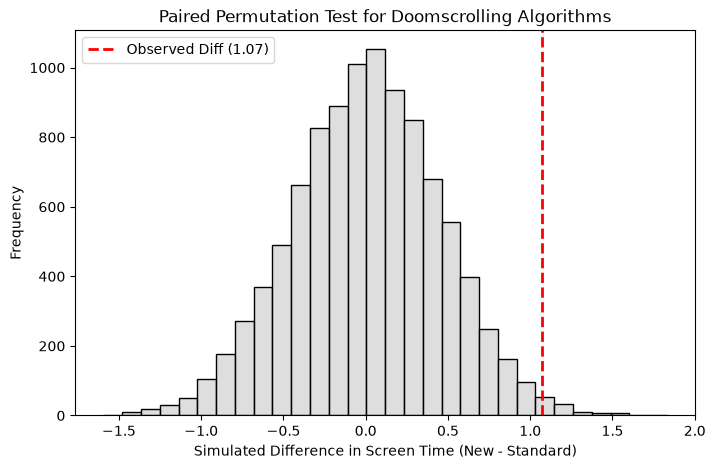

P-value for Paired Permutation Test (Doomscrolling Algorithms): 0.0172


In [14]:
# paired permutation test
def paired_permutation_test(df, col1, col2, n_permutations=10000):
    observed_difference = df[col2] - df[col1]
    observed_stat = observed_difference.mean()
    null_distribution = []
    for _ in range(n_permutations):
        permuted_difference = observed_difference.copy()
        flip = np.random.choice([True, False], size=len(permuted_difference))
        permuted_difference[flip] = -permuted_difference[flip]
        null_distribution.append(permuted_difference.mean())
    null_distribution = np.array(null_distribution)
    p_value = (np.abs(null_distribution) >= np.abs(observed_stat)).mean()
    return observed_stat, p_value, null_distribution

obs_diff, p_value, null_dist = paired_permutation_test(df_doomscrolling, 'standard_time', 'new_time', n_permutations=10000)

plt.figure(figsize=(8, 5))
sns.histplot(null_dist, bins=30, color='lightgray', edgecolor='black')
plt.axvline(obs_diff, color='red', linestyle='dashed', linewidth=2, label=f'Observed Diff ({obs_diff:.2f})')
plt.title('Paired Permutation Test for Doomscrolling Algorithms')
plt.xlabel('Simulated Difference in Screen Time (New - Standard)')
plt.ylabel('Frequency')
plt.legend()
plt.show()

print(f"P-value for Paired Permutation Test (Doomscrolling Algorithms): {p_value:.4f}")

Write a one-paragraph summary of the results for the doomscrolling algorithms. Include the observed difference, the p-value, and a conclusion on whether the new algorithm significantly increases screen time. Be sure to include what the hypothesis test is testing.

Findings: The paired permutation test evaluates whether the new deep-learning algorithm significantly increases user engagement compared to the standard feed, testing the null hypothesis that there is no net difference in individual daily screen time between the two algorithms. Across the 1,000 tested users, screen time averaged 123.32 minutes on the standard feed and 124.39 minutes on the new feed, producing an observed difference of 1.07 minutes. A 10,000-iteration paired permutation test—which randomly flipped the sign of each user's difference to simulate the null distribution—yielded a p-value of 0.0172. Because this p-value is less than the standard significance threshold a = 0.05, we reject the null hypothesis and conclude that the new algorithm results in a statistically significant increase in daily screen time.   